In [1]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import os
import numpy as np

from scipy.signal import savgol_filter
from scipy.signal import welch
from scipy.optimize import curve_fit


In [2]:
#Data loading of temperature end voltages
def convert_and_clean(file_path):

    new_path = file_path.replace('.txt', '.parquet')

    if os.path.exists(new_path):
        print(f'Loading the existing compressed file: {new_path}')
        df = pd.read_parquet(new_path)
        return df

    try:
        print(f"Loading {file_path}...")
     
        df = pd.read_csv(file_path, sep='\t', header=None)
        df.columns = df.columns.astype(str) 
        
   
        print(f"Saving to {new_path}...")
        df.to_parquet(new_path, compression='snappy')

            
        return df
        
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Execution
file_temp = 'DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_temp2026-04-17_13-16.txt'
file_volt = 'DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_volt2026-04-17_13-17.txt'

df_temps = convert_and_clean(file_temp)
df_volts = convert_and_clean(file_volt)

cols_temps = [
    'date', 'unix_time', 
    'temp_1', 'temp_2', 'temp_3', 'temp_4', 
    'temp_5', 'temp_6', 'temp_7', 'temp_8'
]

cols_volts = ['date','unix_time','volts']
df_temps.columns = cols_temps
df_volts.columns = cols_volts

#conversion of the date in a usable format for plotting
df_temps['date'] = pd.to_datetime(df_temps['date'],errors='coerce')
df_volts['date'] = pd.to_datetime(df_volts['date'],errors='coerce')
df_volts['volts'] *= -1

print(df_temps.head())
print(df_volts.head())

Loading the existing compressed file: DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_temp2026-04-17_13-16.parquet
Loading the existing compressed file: DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_volt2026-04-17_13-17.parquet
                        date     unix_time  temp_1  temp_2  temp_3  temp_4  \
0 2026-04-17 13:16:51.269033  1.776425e+09  295.44  688.76   688.9  688.81   
1 2026-04-17 13:16:51.445341  1.776425e+09  295.44  688.76   688.9  688.81   
2 2026-04-17 13:16:51.545822  1.776425e+09  295.44  688.76   688.9  688.81   
3 2026-04-17 13:16:51.625451  1.776425e+09  295.44  688.76   688.9  688.81   
4 2026-04-17 13:16:51.715455  1.776425e+09  295.44  688.76   688.9  688.81   

   temp_5  temp_6  temp_7  temp_8  
0  295.76  295.86   295.3  295.51  
1  295.76  295.86   295.3  295.51  
2  295.76  295.86   295.3  295.51  
3  295.76  295.86   295.3  295.51  
4  295.76  295.86   295.3  295.51  
                        date     unix_t

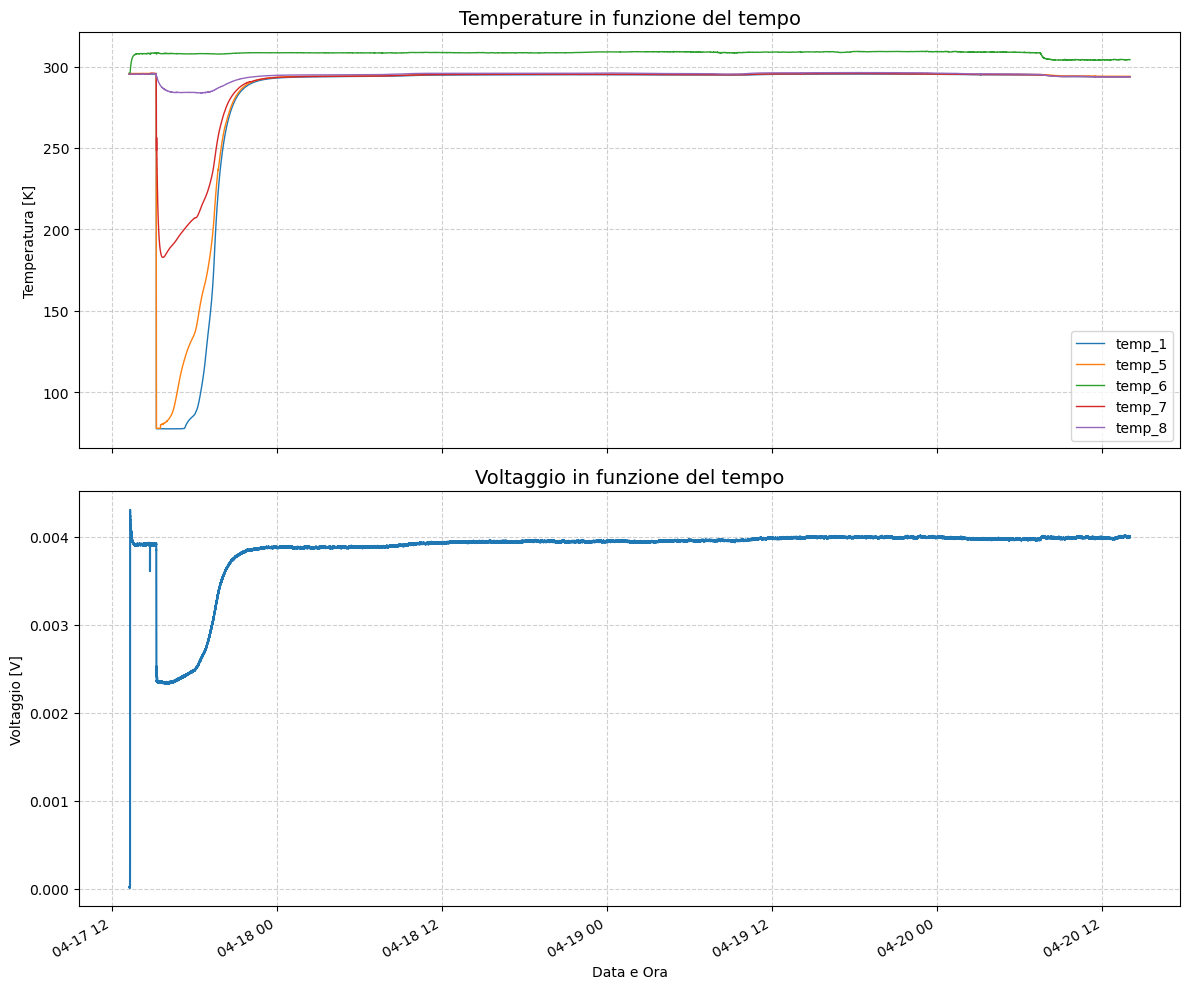

In [3]:
# Plot of the signals of temperatures and votlages
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

#Array of the functioning probes
probes= [1,5,6,7,8]

for i in probes:
    col = f'temp_{i}'
    ax1.plot(df_temps['date'], df_temps[col], label=col, linewidth=1)

ax1.set_title('Temperature in funzione del tempo', fontsize=14)
ax1.set_ylabel('Temperatura [K]')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='lower right')

ax2.plot(df_volts['date'], df_volts['volts'], label='Voltaggio', linewidth=1.5)

ax2.set_title('Voltaggio in funzione del tempo', fontsize=14)
ax2.set_xlabel('Data e Ora')
ax2.set_ylabel('Voltaggio [V]')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.gcf().autofmt_xdate()

plt.tight_layout()
plt.show()



## Noise Temperature

### DA FARE LA REGRESSIONE LINEARE CON LA MATRICE DI COVARIANZA DEI PARAMETRI PER OTTENERE L'INCERTEZZA SULLA T-NOISE

In [4]:
# mask to isolate
mask_volts = (df_volts['date'] >= '2026-04-17 15:20:00') & (df_volts['date'] <= '2026-04-18 00:20:00')
mask_temps = (df_temps['date'] >= '2026-04-17 15:20:00') & (df_temps['date'] <= '2026-04-18 00:20:00')


In [5]:
#extraction of T_H e T_C to evaluate Y-factor
def sigm(x, L ,x0, k, b):
    return  L / (1 + np.exp(-k*(x-x0))) + b
#fit on the temperature

time_data = df_temps['unix_time'][mask_temps].values
temp_data = df_temps['temp_1'][mask_temps].values

time_shifted = time_data - np.median(time_data)


p0 = [np.ptp(temp_data), 0, 1e-8, np.min(temp_data)]


popt, pcov = curve_fit(sigm, time_shifted, temp_data, p0=p0)
L_T, x0_T, k_T, b_T = popt
print(f"Fit results: L={L_T:.2f}, x0={x0_T:.2f}, k={k_T:.4e}, b={b_T:.2f}")


#fit on voltages

time_data_volts = df_volts['unix_time'][mask_volts].values
temp_data_volts = df_volts['volts'][mask_volts].values

time_shifted_volts = time_data_volts - np.median(time_data_volts)


p0 = [np.ptp(temp_data_volts), 0, 1e-8, np.min(temp_data_volts)]


popt, pcov = curve_fit(sigm, time_shifted_volts, temp_data_volts, p0=p0)
L_V, x0_V, k_V, b_V = popt
print(f"Fit results: L={L_V:.2f}, x0={x0_V:.2f}, k={k_V:.4e}, b={b_V:.2f}")

Fit results: L=213.32, x0=-593.43, k=6.0820e-04, b=77.15
Fit results: L=0.00, x0=-1441.71, k=5.0042e-04, b=0.00


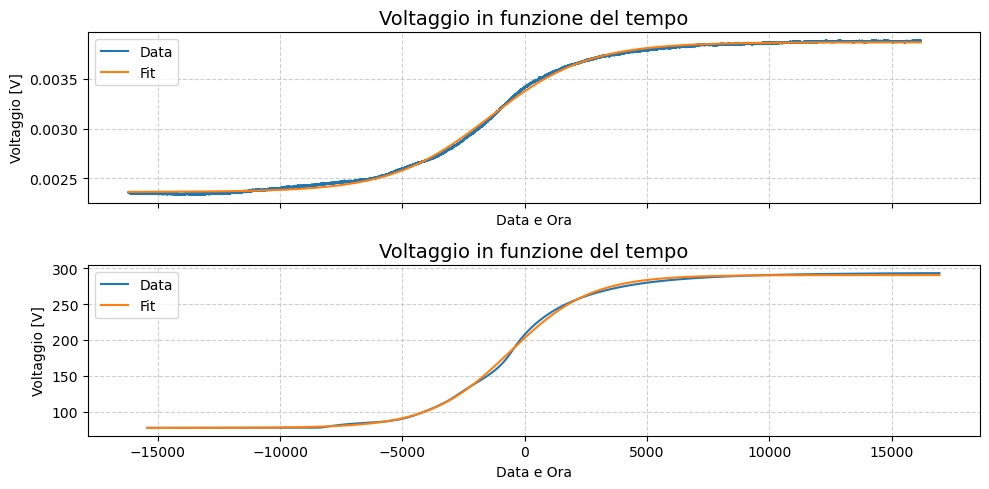

In [6]:
fig,(ax1,ax2) = plt.subplots(2,1, sharex= True, figsize=(10,5))

ax1.plot(time_shifted_volts,temp_data_volts,label="Data")
ax1.plot(time_shifted_volts,sigm(time_shifted_volts,L_V, x0_V, k_V, b_V),label="Fit")

ax1.set_title('Voltaggio in funzione del tempo', fontsize=14)
ax1.set_xlabel('Data e Ora')
ax1.set_ylabel('Voltaggio [V]')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

#probe 1 is under the feedhorn in the liquid nitrogenum
ax2.plot(time_shifted, df_temps['temp_1'][mask_temps],label="Data")
ax2.plot(time_shifted, sigm(time_shifted,L_T,x0_T, k_T, b_T),label="Fit")

ax2.set_title('Voltaggio in funzione del tempo', fontsize=14)
ax2.set_xlabel('Data e Ora')
ax2.set_ylabel('Voltaggio [V]')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

fig.tight_layout()

In [7]:
#computation of T_noise

T_H = L_T+b_T #from the interpretability of the sigmoid model
T_C = b_T


print(f"T hot: {T_H}, T cold: {T_C}")

V_H = L_V+b_V
V_C = b_V


print(f"V hot: {V_H}, V cold: {V_C}")

#Y-factor
Y = V_H/V_C

#T noise
T_N = (T_H-Y*T_C)/(Y-1)

print(f"T noise: {T_N}")

T hot: 290.47106883055477, T cold: 77.15022009992352
V hot: 0.0038693089105570552, V cold: 0.002360320673351472
T noise: 256.5207767318391


## Noise measure

In [8]:
#mask the data to esclude the initial transient
mask = (df_volts['date'] >= '2026-04-18 12:00:00') 
smoothed_voltages = savgol_filter(df_volts['volts'][mask], window_length=11, polyorder=3)
 

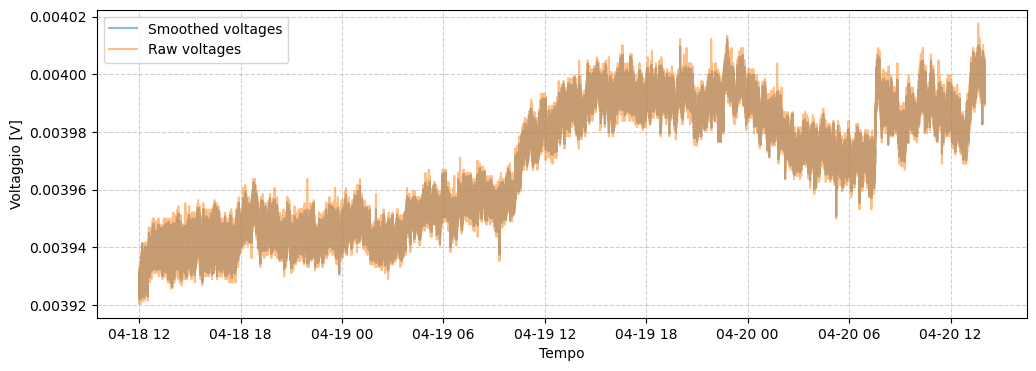

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(df_volts['date'][mask],smoothed_voltages,label = 'Smoothed voltages',alpha = 0.5)
ax.plot(df_volts['date'][mask],df_volts['volts'][mask],label = 'Raw voltages',alpha = 0.5)
ax.set_xlabel('Tempo')
ax.set_ylabel('Voltaggio [V]')
ax.grid(True, linestyle='--', alpha=0.6)

ax.legend()


In [10]:
# dt sampling rate of the multimeter
dt = 0.2
fs = 1.0 / dt


frequencies, psd = welch(smoothed_voltages, fs=fs,nperseg=1024)

#low / high frequencies mask for fit (and exclude the 0.0 freq.)
lf_mask = (frequencies < 0.5) & (frequencies > 0.0)

hf_mask = (frequencies > 0.5)

lf=frequencies[lf_mask]
hf=frequencies[hf_mask]

l_psd=psd[lf_mask]
h_psd=psd[hf_mask]


def f1_noise(f,a):
    return a/f

def white(f,k):
    return [k for _ in f]

a,pcov = curve_fit(f1_noise,lf,l_psd)
k,pcov = curve_fit(white,hf,h_psd)


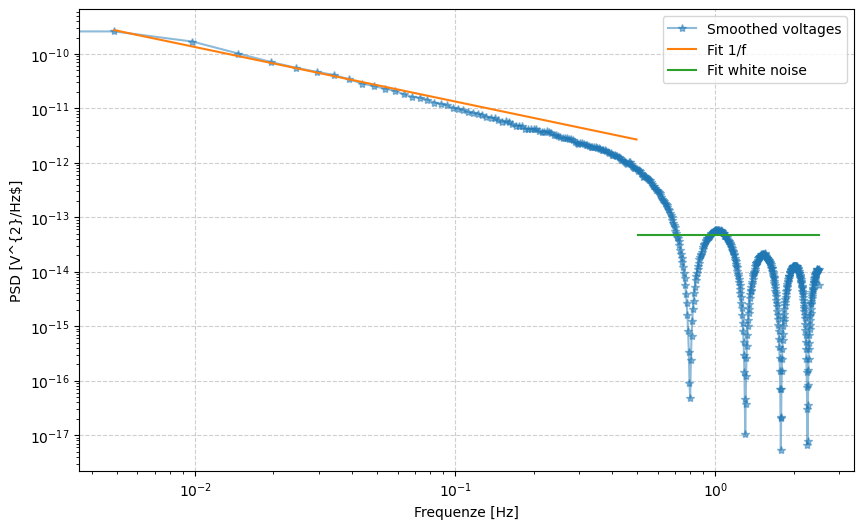

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.loglog(frequencies,psd,label = 'Smoothed voltages',alpha = 0.5, marker = '*')
ax.plot(lf,f1_noise(lf,a),label=r"Fit 1/f")
ax.plot(hf,white(hf,k),label=r"Fit white noise")
ax.set_xlabel('Frequenze [Hz]')
ax.set_ylabel(r'PSD [V^{2}/Hz$]')
ax.grid(True, linestyle='--', alpha=0.6)


ax.legend()
